# CLIP ViT-L/14 (8-bit): upload-time encoding (Stage 1) vs query-time retrieval (Stage 2)
**Stage 1 (once per video, at upload):** decode @1 fps -> preprocess -> vision encoder -> projection -> normalize -> cache vectors to disk.
**Stage 2 (every query, on cached vectors):** text encode -> text projection -> similarity -> threshold -> matching timestamps.
Enable **GPU** and **Internet** in Kaggle.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "bitsandbytes", "accelerate"])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 12.8 MB/s eta 0:00:00


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-U', 'bitsandbytes', 'accelerate'], returncode=0)

In [2]:
import time, math, numpy as np, pandas as pd, torch, cv2
from collections import defaultdict
from transformers import CLIPModel, CLIPProcessor, BitsAndBytesConfig

VIDEO_PATH = "/kaggle/input/datasets/seewhee1130/video-dataset-krishna/videoplayback.mp4"
MODEL_NAME = "openai/clip-vit-large-patch14"
QUERIES    = ["lion", "elephant", "a person talking", "a car"]   # first one is the main query
SAMPLE_FPS = 1
BATCH_SIZE = 32
THRESHOLD  = 0.20      # uncalibrated cosine cutoff (your first run: p95=0.192, p99=0.208, max=0.249); judge it by the top-frame images below
TOP_K      = 3         # number of best-matching frames to display
MIN_GAP_SEC = 0        # >0 forces the shown frames to be at least this many seconds apart (avoids near-duplicate neighbours)
USE_8BIT   = True      # False = fp16
Q_REPS     = 20        # repetitions per query for Stage 2 (median reported)
CACHE_PATH = "/kaggle/working/video_vectors.pt"
assert torch.cuda.is_available(), "Enable a GPU"

In [3]:
# ---- model load (one-time app startup; NOT in either stage) ----
t0 = time.perf_counter()
kw = dict(quantization_config=BitsAndBytesConfig(load_in_8bit=True, llm_int8_skip_modules=["visual_projection", "text_projection"]),
          device_map={"": 0}) if USE_8BIT else {}
model = CLIPModel.from_pretrained(MODEL_NAME, torch_dtype=torch.float16, **kw)
if not USE_8BIT: model = model.cuda()
model.eval(); model.requires_grad_(False)
processor = CLIPProcessor.from_pretrained(MODEL_NAME); tokenizer = processor.tokenizer
vision_model, visual_projection = model.vision_model, model.visual_projection
text_model, text_projection = model.text_model, model.text_projection
torch.cuda.synchronize()
print(f"Model load: {time.perf_counter()-t0:.1f}s | mode: {'8-bit' if USE_8BIT else 'fp16'} | GPU mem: {torch.cuda.memory_allocated()/2**20:.0f} MiB")

def gpu(store, name, fn):
    a, b = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
    a.record(); out = fn(); b.record(); store[name].append((a, b)); return out
def resolve(store):
    torch.cuda.synchronize(); return {k: sum(a.elapsed_time(b) for a, b in v) for k, v in store.items()}   # ms

# warm-up (kernel init not counted)
with torch.inference_mode():
    d = torch.zeros(BATCH_SIZE, 3, 224, 224, dtype=torch.float16, device="cuda")
    visual_projection(vision_model(pixel_values=d).pooler_output)
    ti = {k: v.cuda() for k, v in tokenizer(["warmup"], padding=True, return_tensors="pt").items()}
    text_projection(text_model(**ti).pooler_output); torch.cuda.synchronize()

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Model load: 19.2s | mode: 8-bit | GPU mem: 448 MiB


In [4]:
# ================= STAGE 1: upload-time encoding =================
cap = cv2.VideoCapture(VIDEO_PATH); assert cap.isOpened()
src_fps = cap.get(cv2.CAP_PROP_FPS); n_src = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.release()
duration = n_src / src_fps
indices = [min(int(round(i * src_fps / SAMPLE_FPS)), n_src - 1) for i in range(int(duration * SAMPLE_FPS))]
timestamps = np.array([i / SAMPLE_FPS for i in range(len(indices))])
print(f"Video: {duration:.1f}s | {src_fps:.2f} fps | {n_src} source frames | sampling {SAMPLE_FPS} fps -> {len(indices)} frames")

@torch.inference_mode()
def stage1():
    cpu = defaultdict(float); ev = defaultdict(list); vecs = []
    torch.cuda.synchronize(); t_start = time.perf_counter()
    cap = cv2.VideoCapture(VIDEO_PATH); buf, j, pos = [], 0, 0
    def flush():
        nonlocal buf
        if not buf: return
        t = time.perf_counter(); px = processor.image_processor(images=buf, return_tensors="pt")["pixel_values"]; cpu["preprocess"] += time.perf_counter() - t
        px = gpu(ev, "upload to GPU", lambda: px.cuda().half())
        raw = gpu(ev, "vision encoder", lambda: vision_model(pixel_values=px).pooler_output)
        emb = gpu(ev, "image projection", lambda: visual_projection(raw))
        vecs.append(gpu(ev, "L2 normalize", lambda: emb / emb.norm(dim=-1, keepdim=True)))
        buf = []
    while j < len(indices):
        t = time.perf_counter(); ok = cap.grab(); cpu["decode"] += time.perf_counter() - t
        if not ok: break
        fr = None
        while j < len(indices) and indices[j] == pos:
            if fr is None:
                t = time.perf_counter(); ok, bgr = cap.retrieve(); fr = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB); cpu["decode"] += time.perf_counter() - t
            buf.append(fr); j += 1
        pos += 1
        if len(buf) >= BATCH_SIZE: flush()
    flush(); cap.release()
    E = gpu(ev, "assemble cache", lambda: torch.cat(vecs))
    g = resolve(ev)
    t = time.perf_counter(); torch.save(E.cpu(), CACHE_PATH); cpu["write cache to disk"] = time.perf_counter() - t
    wall = time.perf_counter() - t_start
    return E, {k: v * 1000 for k, v in cpu.items()}, g, wall * 1000

E, s1_cpu, s1_gpu, s1_wall = stage1()
assert E.shape[0] == len(timestamps)
rows = [("decode (CPU)", s1_cpu["decode"]), ("preprocess (CPU)", s1_cpu["preprocess"]), ("upload to GPU", s1_gpu["upload to GPU"]),
        ("vision encoder", s1_gpu["vision encoder"]), ("image projection", s1_gpu["image projection"]),
        ("L2 normalize", s1_gpu["L2 normalize"]), ("assemble cache", s1_gpu["assemble cache"]), ("write cache to disk", s1_cpu["write cache to disk"])]
s1_total = sum(r[1] for r in rows)
df1 = pd.DataFrame([(n, f"{v/1000:.2f} s", f"{v/s1_total*100:.1f}%") for n, v in rows] + [("STAGE 1 TOTAL (sum of steps)", f"{s1_total/1000:.2f} s", "100%")],
                   columns=["Stage 1 step (once per video)", "Time", "% of stage"])
print("\n" + df1.to_string(index=False))
print(f"\nWall-clock Stage 1: {s1_wall/1000:.2f}s | per frame: {s1_total/len(E):.1f} ms | per minute of video: {s1_total/1000/(duration/60):.1f} s | {duration/(s1_total/1000):.1f}x real time")
print(f"Cache: {tuple(E.shape)} fp16 = {E.numel()*2/2**20:.2f} MiB for this video ({E.numel()*2/1024/(duration/60):.0f} KiB per minute of video)")

Video: 560.8s | 29.97 fps | 16808 source frames | sampling 1 fps -> 560 frames

Stage 1 step (once per video)    Time % of stage
                 decode (CPU) 21.53 s      63.2%
             preprocess (CPU)  3.28 s       9.6%
                upload to GPU  0.08 s       0.2%
               vision encoder  9.08 s      26.6%
             image projection  0.00 s       0.0%
                 L2 normalize  0.09 s       0.3%
               assemble cache  0.00 s       0.0%
          write cache to disk  0.01 s       0.0%
 STAGE 1 TOTAL (sum of steps) 34.06 s       100%

Wall-clock Stage 1: 34.20s | per frame: 60.8 ms | per minute of video: 3.6 s | 16.5x real time
Cache: (560, 768) fp16 = 0.82 MiB for this video (90 KiB per minute of video)


In [5]:
# ================= STAGE 2: query-time retrieval on cached vectors =================
def segments_from(match, ts):
    segs, start = [], None
    for i, m in enumerate(match):
        if m and start is None: start = i
        if start is not None and (not m or i == len(match) - 1):
            segs.append((ts[start], ts[i] if m else ts[i - 1])); start = None
    return segs

@torch.inference_mode()
def stage2(query, E, ts, thr):
    cpu = {}; ev = defaultdict(list)
    torch.cuda.synchronize(); t = time.perf_counter()
    ti = {k: v.cuda() for k, v in tokenizer([query], padding=True, return_tensors="pt").items()}
    torch.cuda.synchronize(); cpu["tokenize + upload query"] = (time.perf_counter() - t) * 1000
    h = gpu(ev, "text encoder", lambda: text_model(**ti).pooler_output)
    tv = gpu(ev, "text projection", lambda: text_projection(h))
    s = gpu(ev, "normalize query + similarity", lambda: (E @ (tv / tv.norm(dim=-1, keepdim=True)).T).squeeze(1))
    g = resolve(ev)
    t = time.perf_counter()
    scores = s.float().cpu().numpy(); match = scores >= thr; segs = segments_from(match, ts)
    cpu["GPU->CPU + threshold + segments"] = (time.perf_counter() - t) * 1000
    return {**cpu, **g}, scores, match, segs

STEPS = ["tokenize + upload query", "text encoder", "text projection", "normalize query + similarity", "GPU->CPU + threshold + segments"]
fmt = lambda s: f"{int(s//60)}:{int(s%60):02d}"
for _ in range(5): stage2(QUERIES[0], E, timestamps, THRESHOLD)   # warm-up

per_query = {}
for q in QUERIES:
    runs = [stage2(q, E, timestamps, THRESHOLD) for _ in range(Q_REPS)]
    med = {k: float(np.median([r[0][k] for r in runs])) for k in STEPS}
    tot = [sum(r[0][k] for k in STEPS) for r in runs]
    per_query[q] = (med, float(np.median(tot)), float(np.std(tot, ddof=1)), runs[-1])

med, tot, sd, last = per_query[QUERIES[0]]
df2 = pd.DataFrame([(k, f"{med[k]:.3f} ms", f"{med[k]/sum(med.values())*100:.1f}%") for k in STEPS] +
                   [(f"STAGE 2 TOTAL per query (median of {Q_REPS}, sd {sd:.3f} ms)", f"{tot:.3f} ms", "100%")],
                   columns=[f"Stage 2 step (query {QUERIES[0]!r}, {len(E)} cached vectors)", "Time", "% of stage"])
print(df2.to_string(index=False))

# cold start: loading the cache back (what an app pays once per video per session)
del_E = E; t = time.perf_counter(); E_loaded = torch.load(CACHE_PATH).cuda(); torch.cuda.synchronize()
print(f"\nOne-time cache load (disk -> GPU): {(time.perf_counter()-t)*1000:.1f} ms (OS page cache is warm, so a cold disk will be slower)")
assert torch.equal(E_loaded, E)

print("\nPer-query latency (all on the same cached vectors):")
for q, (m, t_, s_, r) in per_query.items():
    print(f"  {q!r:22s} {t_:7.3f} ms  | matches at threshold {THRESHOLD}: {int(r[2].sum())} frames, {len(r[3])} segment(s)")

scores, match, segs = last[1], last[2], last[3]
print(f"\nQuery {QUERIES[0]!r}: score percentiles " + ", ".join(f"p{p}={np.percentile(scores,p):.3f}" for p in (5, 25, 50, 75, 90, 95, 99)))
print(f"Matches @ {THRESHOLD}: {int(match.sum())} frames | segments:", ", ".join(f"{fmt(a)}-{fmt(b)}" for a, b in segs) if segs else "none")
print("Top 10:", [(fmt(timestamps[i]), round(float(scores[i]), 3)) for i in np.argsort(-scores)[:10]])
print(f"\nStage 1 total {s1_total/1000:.2f}s (once)  vs  Stage 2 {tot:.2f} ms per query -> re-encoding per query would be {s1_total/tot:,.0f}x slower")

    Stage 2 step (query 'lion', 560 cached vectors)      Time % of stage
                            tokenize + upload query  0.286 ms       0.5%
                                       text encoder 51.835 ms      98.8%
                                    text projection  0.084 ms       0.2%
                       normalize query + similarity  0.125 ms       0.2%
                    GPU->CPU + threshold + segments  0.140 ms       0.3%
STAGE 2 TOTAL per query (median of 20, sd 1.269 ms) 52.467 ms       100%

One-time cache load (disk -> GPU): 2.0 ms (OS page cache is warm, so a cold disk will be slower)

Per-query latency (all on the same cached vectors):
  'lion'                  52.467 ms  | matches at threshold 0.2: 15 frames, 7 segment(s)
  'elephant'              50.859 ms  | matches at threshold 0.2: 0 frames, 0 segment(s)
  'a person talking'      51.148 ms  | matches at threshold 0.2: 1 frames, 1 segment(s)
  'a car'                 51.436 ms  | matches at threshold 0.2: 2 frames

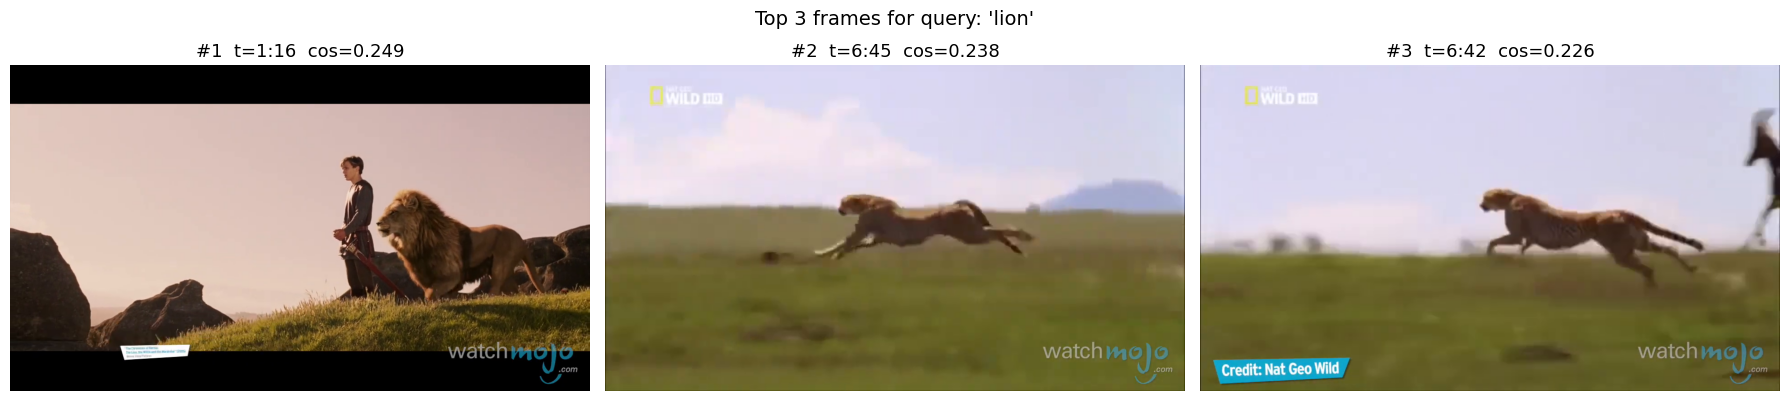

In [6]:
# ================= Show the top-matching frames (display only, not part of either stage) =================
import matplotlib.pyplot as plt
order, picked = np.argsort(-scores), []
for i in order:
    if all(abs(timestamps[i] - timestamps[k]) >= MIN_GAP_SEC for k in picked): picked.append(int(i))
    if len(picked) == TOP_K: break
cap = cv2.VideoCapture(VIDEO_PATH)
fig, axes = plt.subplots(1, len(picked), figsize=(6 * len(picked), 4.2))
axes = np.atleast_1d(axes)
for ax, i, rank in zip(axes, picked, range(1, len(picked) + 1)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, indices[i]); ok, bgr = cap.read()
    if ok: ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(f"#{rank}  t={fmt(timestamps[i])}  cos={scores[i]:.3f}", fontsize=13); ax.axis("off")
cap.release(); plt.suptitle(f"Top {len(picked)} frames for query: {QUERIES[0]!r}", fontsize=14); plt.tight_layout()
plt.savefig("/kaggle/working/top_frames.png", dpi=110); plt.show()

In [7]:
# ================= Design aid: how does the similarity search scale with cache size? =================
with torch.inference_mode():
    tv = text_projection(text_model(**{k: v.cuda() for k, v in tokenizer([QUERIES[0]], padding=True, return_tensors="pt").items()}).pooler_output)
    tv = (tv / tv.norm(dim=-1, keepdim=True)).squeeze(0)
    def search(Eb): return (Eb @ tv >= THRESHOLD).nonzero()      # full linear scan + threshold, stays on GPU
    out = []
    for N in [len(E), 100_000, 1_000_000]:
        Eb = E.repeat(math.ceil(N / len(E)), 1)[:N].contiguous()
        for _ in range(5): search(Eb)
        ts_ = []
        for _ in range(30):
            a, b = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            a.record(); search(Eb); b.record(); torch.cuda.synchronize(); ts_.append(a.elapsed_time(b))
        out.append((f"{N:,}", f"{N/SAMPLE_FPS/3600:,.1f} h of video @ {SAMPLE_FPS} fps", f"{Eb.numel()*2/2**20:,.1f} MiB", f"{np.median(ts_):.3f} ms"))
        del Eb; torch.cuda.empty_cache()
print(pd.DataFrame(out, columns=["Cached vectors", "Equivalent video length", "Cache size (fp16, 768-d)", "Linear-scan search (median)"]).to_string(index=False))
print("Synthetic: your vectors tiled to size, GPU-resident. Shows scan cost only, not text encoding or CPU round-trips.")

Cached vectors  Equivalent video length Cache size (fp16, 768-d) Linear-scan search (median)
           560   0.2 h of video @ 1 fps                  0.8 MiB                    0.112 ms
       100,000  27.8 h of video @ 1 fps                146.5 MiB                    1.001 ms
     1,000,000 277.8 h of video @ 1 fps              1,464.8 MiB                   10.302 ms
Synthetic: your vectors tiled to size, GPU-resident. Shows scan cost only, not text encoding or CPU round-trips.
